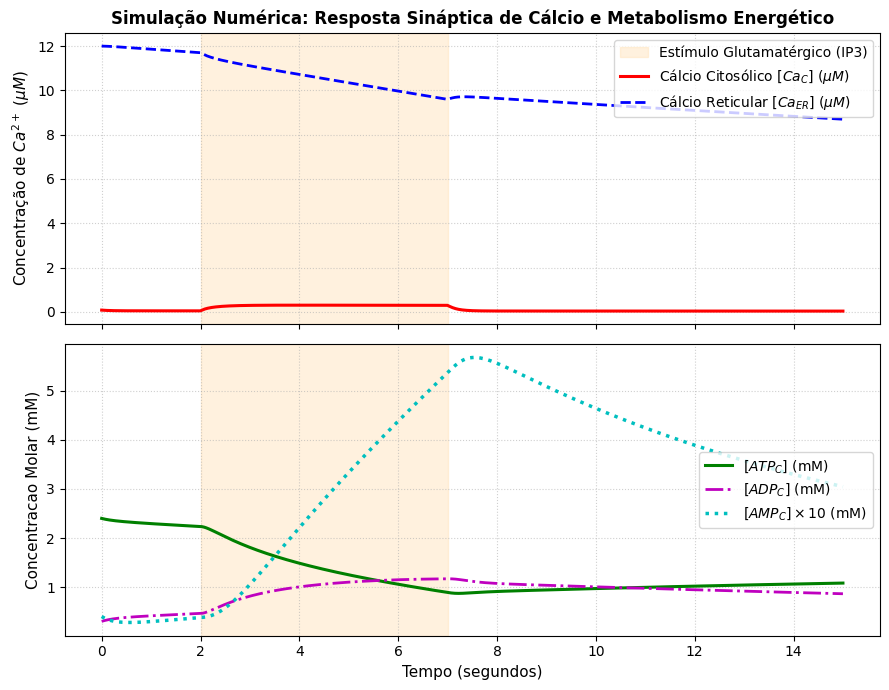

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. DEFINICAO DO SISTEMA DE EDOs ACOPLADAS (LEUNG & RANGAMANI)
def modelo_sinapse(t, y, params):
    CaC, CaER, ATP, ADP, AMP = y
    
    # Restricao de nao-negatividade por estabilidade numerica
    CaC = max(CaC, 0.001)
    CaER = max(CaER, 0.001)
    ATP = max(ATP, 0.01)
    ADP = max(ADP, 0.01)
    AMP = max(AMP, 0.001)
    
    # Fluxos de Calcio (Modulo I)
    J_leak = params['k_leak'] * (CaER - CaC)
    J_serca = params['V_serca'] * (CaC**2) / (params['K_serca']**2 + CaC**2)
    J_pm = params['V_pm'] * CaC / (params['K_pm'] + CaC)
    J_ryr = params['k_ryr'] * CaC
    
    # Pulso presinaptico de glutamato/IP3 entre t = 2s e t = 7s
    J_ip3 = params['k_ip3'] if (2.0 <= t <= 7.0) else 0.0
    J_buff = params['k_buff'] * CaC
    
    # Fluxos Metabolicos (Modulo II)
    J_atpca = 0.8 * J_serca + 0.4 * J_pm
    J_op = params['V_op'] * (CaC**2) / (params['K_op']**2 + CaC**2) * ADP
    J_glyc = params['V_glyc'] * ADP
    K_eq_ak = 0.45
    J_ak = params['k_ak'] * (ADP**2 - (ATP * AMP) / K_eq_ak)
    J_ampk = params['k_ampk'] * AMP
    
    # EDOs do Calcio
    dCaC_dt = J_ryr + J_ip3 - J_serca - J_pm + J_leak - J_buff
    dCaER_dt = -J_ryr - J_ip3 + J_serca - J_leak
    
    # EDOs dos Nucleotideos de Adenina
    dATP_dt = J_op + J_glyc - J_atpca + J_ak
    dADP_dt = J_atpca - J_op - J_glyc - 2 * J_ak
    dAMP_dt = J_ak - J_ampk
    
    return [dCaC_dt, dCaER_dt, dATP_dt, dADP_dt, dAMP_dt]

# 2. PARAMETROS FISIOLOGICOS E CONDICOES INICIAIS
params = {
    'k_leak': 0.02,
    'V_serca': 1.5,
    'K_serca': 0.2,
    'V_pm': 0.5,
    'K_pm': 0.1,
    'k_ryr': 0.05,
    'k_ip3': 1.2,
    'k_buff': 0.01,
    'V_glyc': 0.1,
    'V_op': 0.8,
    'K_op': 0.25,
    'k_ak': 0.5,
    'k_ampk': 0.1
}

# Estado Inicial: [CaC (uM), CaER (uM), ATP (mM), ADP (mM), AMP (mM)]
y0 = [0.08, 12.0, 2.4, 0.3, 0.04]
t_span = (0, 15)
t_eval = np.linspace(0, 15, 1000)


# 3. INTEGRACAO NUMERICA IMPLICITA (METODO RADAU PARA SISTEMAS RIGIDOS)
sol = solve_ivp(modelo_sinapse, t_span, y0, args=(params,), t_eval=t_eval, method='Radau')


# 4. PLOTAGEM DOS GRAFICOS DE RESULTADOS

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

# Destaque do Periodo de Estímulo Glutamatergico (IP3)
ax1.axvspan(2, 7, color='navajowhite', alpha=0.4, label='Estímulo Glutamatérgico (IP3)')
ax2.axvspan(2, 7, color='navajowhite', alpha=0.4)

# Painel 1: Dinamica de Calcio
ax1.plot(sol.t, sol.y[0], 'r-', linewidth=2.2, label=r'Cálcio Citosólico $[Ca_C]$ ($\mu M$)')
ax1.plot(sol.t, sol.y[1], 'b--', linewidth=2.0, label=r'Cálcio Reticular $[Ca_{ER}]$ ($\mu M$)')
ax1.set_ylabel(r'Concentração de $Ca^{2+}$ ($\mu M$)', fontsize=11)
ax1.set_title('Simulação Numérica: Resposta Sináptica de Cálcio e Metabolismo Energético', fontsize=12, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', frameon=True)

# Painel 2: Dinamica de Nucleotideos (ATP, ADP, AMP)
ax2.plot(sol.t, sol.y[2], 'g-', linewidth=2.2, label=r'$[ATP_C]$ (mM)')
ax2.plot(sol.t, sol.y[3], 'm-.', linewidth=2.0, label=r'$[ADP_C]$ (mM)')
ax2.plot(sol.t, sol.y[4] * 10, 'c:', linewidth=2.5, label=r'$[AMP_C] \times 10$ (mM)')
ax2.set_xlabel('Tempo (segundos)', fontsize=11)
ax2.set_ylabel('Concentracao Molar (mM)', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='center right', frameon=True)

plt.tight_layout()

# dpi=300 garante alta qualidade (ótimo para artigos ou relatórios)
plt.savefig('resposta_sinaptica.png', dpi=300, bbox_inches='tight')

plt.show()